# Adaptive layer additions — full evaluation (one notebook)

Runs the whole evaluation of branch `feature/adaptive-signals-lite` and shows the results here. Everything is also stored on disk. It covers the eight additions: #1 unequal distances (T1/T2), #5 per-collection policy, #6 per-key read-your-own-writes, #8 hysteresis, #9 SAFE latency budget, #10 switch reasons, #11 static MODERATE baseline, #12 pinned primary.

| Step | What | Time (FULL profile) |
|---|---|---|
| 1 | **Settings**: pick a profile, or resume an earlier run by its tag | – |
| 2 | **Plan**: every run listed, with a time estimate and the expected finish time | – |
| 3 | **Preflight checks**: Docker up, no leftover delays, primary pinned, topologies work, tests pass, disk space. *Stops here if any fail.* | ~1 min |
| 4 | **Live checks**: 5 scenarios, one per addition (`benchmark/signals_check.py`). *Stops here if any fail* (`STOP_ON_CHECK_FAIL`) | ~2 min |
| 5 | **Load tests**: 3 network setups (equal 0 ms, T1, T2) × 5 configurations × 6 core workloads = 90 Locust runs of 180 s (SPIKE 108 s) | ~4 h 21 min |
| 6 | **Staleness experiment**: read-after-write staleness on every setup | ~13 min |
| 7 | **Results**: integrity checks, expectations fixed in advance, tables, figures | – |
| 8 | **Store**: a committable copy in `docs/results/signals/<tag>/` | – |

**How to run.** Run All in Jupyter or VS Code with kernel *Python (MongoLayer .venv)*, or headless from a terminal (saves the notebook after every cell):

```
.venv\Scripts\python -m benchmark.run_notebook signals_evaluation.ipynb
```

**Before the ~4 h 35 min run** (`FULL_ALL`, all 10 workloads: ~7 h 40 min). Plug the laptop in. Set Windows sleep to *Never* (Settings → System → Power). Keep Docker Desktop running.

**If it stops** (sleep, crash, Docker restart): set `RUN_TAG` below to the tag printed in step 2 and run again. Finished runs are skipped (each leaves a `.done` marker), and so are finished checks and staleness setups. A run that hangs is killed 2 minutes past its length, retried once, and recorded as failed if the retry fails too, so one stuck run cannot block the evening.

**Why 6 workloads.** READ_HEAVY (FAST + read-your-own-writes), READ_HEAVY_HOTSPOT (cost of routing hot keys to the primary), MODEST_WRITES (MODERATE), BALANCED (the latency budget), MIXED_BURSTY (hysteresis and switching), SPIKE (short bursts). The other four add little for these additions: WRITE_HEAVY and HOTSPOT behave like BALANCED, RAMP only tests a slow ramp-up, HIGH_CONCURRENCY is a load test of the layer itself. Use `FULL_ALL` to include them.

**Why no 5 ms and no 43 ms setup.** 43 ms equal delay is dropped (T1 already has an 86 ms round trip between nodes). 5 ms is left out because these additions behave the same there as at 0 ms (SAFE stays far inside the latency budget). The 2026-10-19 overnight data already showed what 5 ms changes: SAFE writes ~5-10 ms slower, static FAST 1-11% stale. Add `"EQUAL-5"` in `CUSTOM` to include it (+1 h 30 min).

In [2]:
import os

# ---- SETTINGS -------------------------------------------------------------------------------------
PROFILE = os.environ.get("SIGNALS_PROFILE", "FULL")   # "FULL" (~4 h 35 min) | "FULL_ALL" (~7 h 40 min) | "SMOKE" (~14 min) | "CUSTOM"
RUN_TAG = os.environ.get("SIGNALS_RUN_TAG") or None       # None = start a new run; "<tag>" = resume that run

STOP_ON_CHECK_FAIL = True      # do not start the long load tests if a live check fails
RUN_TESTS_IN_PREFLIGHT = True  # run the test suite (112 tests, ~15 s) before starting
STORE_RECORD = PROFILE != "SMOKE"  # copy tables, figures and small CSVs to docs/results/signals/<tag>/

# Used only when PROFILE == "CUSTOM":
CUSTOM = dict(
    setups=["EQUAL-0", "T1", "T2"],   # EQUAL-<one-way ms> (e.g. "EQUAL-5"), T1 (far primary), T2 (regional pair)
    configs=["static_fast", "static_moderate", "static_safe", "adaptive", "adaptive_signals"],
    presets=["READ_HEAVY", "READ_HEAVY_HOTSPOT", "MODEST_WRITES", "BALANCED", "MIXED_BURSTY", "SPIKE"],
    # also available: "WRITE_HEAVY", "HOTSPOT", "RAMP", "HIGH_CONCURRENCY"
    duration_scale=0.6,          # 300 s runs -> 180 s
    fixed_duration_s=None,       # e.g. 60 for every run 60 s
    repeats=1,
    run_checks=True,
    staleness_setups=["EQUAL-0", "T1", "T2"],
    staleness_trials=200,
)

In [3]:
import datetime as dt
import json
import time
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

from benchmark import run_benchmark as rb, signals_eval as ev

PROFILES = {
    "FULL": dict(),   # the defaults of ev.Plan: 3 setups x 5 configs x 6 core workloads, 0.6 x full length, 1 repeat
    "FULL_ALL": dict(presets=list(rb.PRESETS)),   # the same with all 10 workloads
    "SMOKE": dict(setups=["EQUAL-0", "T1"], presets=["READ_HEAVY", "BALANCED"], fixed_duration_s=30,
                  staleness_setups=["EQUAL-0"], staleness_trials=20),
    "CUSTOM": CUSTOM,
}
plan = ev.Plan(**PROFILES[PROFILE])
tag = RUN_TAG or f"{PROFILE}_{dt.datetime.now():%Y-%m-%d_%H%M}"
OUT = ev.out_dir_for(tag)
OUT.mkdir(parents=True, exist_ok=True)
log = ev.Log(OUT / "run_log.txt")
pd.set_option("display.max_colwidth", 120)

rows, total = ev.estimate(plan)
done = sum(ev.is_done(OUT, *c) for c in plan.cells())
meta = ev.write_meta(OUT, plan, tag=tag, profile=PROFILE, started=dt.datetime.now().isoformat(timespec="seconds"))
display(Markdown(f"""**Run tag:** `{tag}` (resume with `RUN_TAG = "{tag}"`)  \n**Output:** `{OUT}`  \n"""
                 f"""**Load-test runs:** {len(plan.cells())} planned, {done} already done  \n"""
                 f"""**Estimated time:** {ev.fmt_hours(total)} (if nothing is done yet) → finishes around """
                 f"""**{(dt.datetime.now() + dt.timedelta(seconds=total)):%a %H:%M}**"""))
display(pd.DataFrame([{"phase": n, "estimate": ev.fmt_hours(s)} for n, s in rows]
                     + [{"phase": "TOTAL", "estimate": ev.fmt_hours(total)}]).style.hide(axis="index"))
display(pd.DataFrame([{"preset": p, "users": plan.params(p)["users"], "spawn rate": plan.params(p)["spawn_rate"],
                       "run length": plan.params(p)["duration"]} for p in plan.presets]).style.hide(axis="index"))

**Run tag:** `FULL_2026-10-19_1452` (resume with `RUN_TAG = "FULL_2026-10-19_1452"`)  
**Output:** `C:\Users\admin\Desktop\Resume\MongoLayer\results\signals_eval\FULL_2026-10-19_1452`  
**Load-test runs:** 90 planned, 0 already done  
**Estimated time:** 4 h 35 min (if nothing is done yet) → finishes around **Mon 19:28**

phase,estimate
live checks (5 scenarios),2 min
load tests EQUAL-0 (5 configs x 6 presets x 1 rep),1 h 27 min
load tests T1 (5 configs x 6 presets x 1 rep),1 h 27 min
load tests T2 (5 configs x 6 presets x 1 rep),1 h 27 min
staleness EQUAL-0,3 min
staleness T1,6 min
staleness T2,4 min
TOTAL,4 h 35 min


preset,users,spawn rate,run length
READ_HEAVY,50,20,180s
READ_HEAVY_HOTSPOT,50,20,180s
MODEST_WRITES,50,20,180s
BALANCED,50,20,180s
MIXED_BURSTY,50,20,180s
SPIKE,50,20,108s


## 3. Preflight checks

In [4]:
t0 = time.monotonic()
pre = ev.preflight(OUT, run_tests=RUN_TESTS_IN_PREFLIGHT)
pre_df = pd.DataFrame(pre, columns=["check", "ok", "detail"])
display(pre_df.style.hide(axis="index").map(lambda v: "color: #1a7f37; font-weight: bold" if v is True
                                               else ("color: #cf222e; font-weight: bold" if v is False else ""), subset=["ok"]))
ev.write_meta(OUT, plan, phase_seconds={"preflight": round(time.monotonic() - t0)})
if not pre_df["ok"].all():
    raise RuntimeError("Preflight failed - fix the failing check(s) above before starting the long runs.")
log.say("preflight: all checks passed")

check,ok,detail
Docker containers mongo1-3 running,True,"running: mongo1, mongo2, mongo3"
no leftover network delays,True,no injected delays
"replica set healthy, mongo1 pinned, direct replication",True,"states {'mongo1': 'PRIMARY', 'mongo2': 'SECONDARY', 'mongo3': 'SECONDARY'}, sync sources {'mongo2': 'mongo1', 'mongo3': 'mongo1'}"
topology T1 can be applied and measured,True,"T1 client round trips mongo1 87.5 ms, mongo2 1.9 ms, mongo3 87.0 ms"
test suite passes,True,112 passed in 13.51s
disk space,True,20.1 GB free


[14:53:20] preflight: all checks passed


## 4. Live checks — one scenario per signal rule

In [5]:
t0 = time.monotonic()
checks = ev.run_live_checks(OUT, log) if plan.run_checks else {}
ev.write_meta(OUT, plan, phase_seconds={"live_checks": round(time.monotonic() - t0)})

def check_summary(name, r):
    pick = {
        "C1": lambda r: f"T1 client: mongo2 {r['T1_client_rtt_ms']['mongo2']} ms, primary mongo1 {r['T1_client_rtt_ms']['mongo1']} ms; "
                        f"T1 nodes {r['T1_node_rtt_ms']} ms; EQUAL-5 nodes {r['EQUAL5_node_rtt_ms']} ms; primary {r['primary']}",
        "C2": lambda r: f"plain FAST {r['plain_fast']['stale']}/100 stale; per-key routing {r['fast_read_own_writes']['stale']}/100, "
                        f"other reads {r['fast_read_own_writes']['other_read_p50_ms']} ms",
        "C3": lambda r: f"floor=SAFE collection under 5% writes -> {r['settings']}",
        "C4": lambda r: f"-> {r['settings']} after {r['after_s']} s: {r['reason'].split('; ')[-1]}",
        "C5": lambda r: f"at {r['with_hysteresis']['write_share_after_drop']:.0%} writes after SAFE: traffic rule -> "
                        f"{r['traffic_rule_only']['settings_after_drop']}, with hysteresis -> {r['with_hysteresis']['settings_after_drop']}",
    }
    try:
        return pick[name](r)
    except Exception:  # noqa: BLE001
        return "(see checks.json)"

if checks:
    display(pd.DataFrame([{"scenario": k, "result": "PASS" if v["pass"] else "FAIL", "what happened": check_summary(k, v),
                           "seconds": v.get("seconds")} for k, v in checks.items()]).style.hide(axis="index").format({"seconds": "{:.0f}"})
            .map(lambda v: "color: #1a7f37; font-weight: bold" if v == "PASS" else ("color: #cf222e; font-weight: bold" if v == "FAIL" else ""),
                 subset=["result"]))
    if STOP_ON_CHECK_FAIL and not all(v["pass"] for v in checks.values()):
        raise RuntimeError("A live check failed - not starting the load tests (set STOP_ON_CHECK_FAIL = False to continue anyway).")

[14:53:40] check C1 (c1_distances): PASS in 20 s
[14:54:15] check C2 (c2_own_writes): PASS in 34 s
[14:54:23] check C3 (c3_policy): PASS in 8 s
[14:54:35] check C4 (c4_budget): PASS in 13 s
[14:55:15] check C5 (c5_hysteresis): PASS in 40 s


scenario,result,what happened,seconds
C1,PASS,"T1 client: mongo2 0.8 ms, primary mongo1 86.7 ms; T1 nodes 86.3 ms; EQUAL-5 nodes 10.3 ms; primary mongo1",20
C2,PASS,"plain FAST 40/100 stale; per-key routing 0/100, other reads 2.0 ms",34
C3,PASS,floor=SAFE collection under 5% writes -> SAFE,8
C4,PASS,-> MODERATE after 4.2 s: SAFE write p95 263 ms > budget 100 ms -> MODERATE,13
C5,PASS,"at 38% writes after SAFE: traffic rule -> MODERATE, with hysteresis -> SAFE",40


## 5. Load tests

One line per finished run, with the time left. The full Locust output is in `run_log.txt`. This is the long part. If it stops, set `RUN_TAG` and run the notebook again.

In [6]:
t0 = time.monotonic()
ran = ev.run_load_tests(OUT, plan, log)
ev.write_meta(OUT, plan, phase_seconds={"load_tests": round(time.monotonic() - t0)})
log.say(f"load tests finished: {ran} runs this session in {ev.fmt_hours(time.monotonic() - t0)}")

[14:55:16] load tests: 90 runs planned, 0 already done, 90 to go
[14:55:17] setup EQUAL-0ms: client equidistant, node pairs 0 ms apart
[14:58:19] [1/90] EQUAL-0ms rep1 static_fast      READ_HEAVY         45307 req, 0 fail, p50 13 ms  | ~4 h 32 min left
[15:01:21] [2/90] EQUAL-0ms rep1 static_fast      READ_HEAVY_HOTSPOT 45344 req, 0 fail, p50 16 ms  | ~4 h 28 min left
[15:04:23] [3/90] EQUAL-0ms rep1 static_fast      MODEST_WRITES      45298 req, 0 fail, p50 20 ms  | ~4 h 24 min left
[15:07:24] [4/90] EQUAL-0ms rep1 static_fast      BALANCED           45264 req, 0 fail, p50 24 ms  | ~4 h 21 min left
[15:10:26] [5/90] EQUAL-0ms rep1 static_fast      MIXED_BURSTY       45305 req, 0 fail, p50 18 ms  | ~4 h 18 min left
[15:12:18] [6/90] EQUAL-0ms rep1 static_fast      SPIKE              27036 req, 0 fail, p50 16 ms  | ~3 h 58 min left
[15:15:20] [7/90] EQUAL-0ms rep1 static_moderate  READ_HEAVY         45302 req, 0 fail, p50 15 ms  | ~3 h 58 min left
[15:18:22] [8/90] EQUAL-0ms rep1 static

## 6. Staleness experiment (write a marker, read it straight back)

In [7]:
t0 = time.monotonic()
ev.run_staleness(OUT, plan, log)
ev.write_meta(OUT, plan, phase_seconds={"staleness": round(time.monotonic() - t0)},
              finished=dt.datetime.now().isoformat(timespec="seconds"))

[19:13:00] staleness EQUAL-0: static_fast 8%, static_moderate 0%, static_safe 0%, adaptive_hot 0%, adaptive_cold 0% (132 s)
[19:18:43] staleness T1: static_fast 46%, static_moderate 0%, static_safe 0%, adaptive_hot 0%, adaptive_cold 33% (343 s)
[19:21:27] staleness T2: static_fast 2%, static_moderate 0%, static_safe 0%, adaptive_hot 0%, adaptive_cold 0% (164 s)


{'plan': {'setups': ['EQUAL-0', 'T1', 'T2'],
  'configs': ['static_fast',
   'static_moderate',
   'static_safe',
   'adaptive',
   'adaptive_signals'],
  'presets': ['READ_HEAVY',
   'READ_HEAVY_HOTSPOT',
   'MODEST_WRITES',
   'BALANCED',
   'MIXED_BURSTY',
   'SPIKE'],
  'duration_scale': 0.6,
  'fixed_duration_s': None,
  'repeats': 1,
  'run_checks': True,
  'staleness_setups': ['EQUAL-0', 'T1', 'T2'],
  'staleness_trials': 200},
 'git_commit': 'd9f7baf+uncommitted',
 'python': '3.13.5',
 'platform': 'Windows-11-10.0.26200-SP0',
 'tag': 'FULL_2026-10-19_1452',
 'profile': 'FULL',
 'started': '2026-10-19T14:52:54',
 'phase_seconds': {'preflight': 26,
  'live_checks': 116,
  'load_tests': 15332,
  'staleness': 639},
 'finished': '2026-10-19T19:21:27'}

## 7. Results

### 7.1 Is the run complete and sound? Did the design's predictions hold?

*Integrity* checks the run itself. *Expectations* are what the design predicts, written down before the run (`benchmark/signals_eval.expectations`). A failed expectation is a finding to report, not something to tune away.

In [8]:
res = ev.analyse(OUT, plan)
df, st = res["summary"], res["staleness"]

def verdict(v):
    return {True: "✅ yes", False: "❌ NO", None: "– not in this run"}[v]

display(Markdown("**Integrity**"))
display(pd.DataFrame([{"check": n, "ok": verdict(ok), "detail": d} for n, ok, d in res["integrity"]]).style.hide(axis="index"))
display(Markdown("**Expectations (fixed before the run)**"))
display(pd.DataFrame([{"expectation": n, "held": verdict(v), "detail": d} for n, v, d in res["expectations"]]).style.hide(axis="index"))

**Integrity**

check,ok,detail
every planned load-test run finished,✅ yes,90/90
no Locust errors or hung runs,✅ yes,none
no run needed a retry,✅ yes,none
no failed requests,✅ yes,0 failed requests in total
every run has staleness probes,✅ yes,all runs probed
live checks all PASS,✅ yes,5/5 PASS
staleness experiment done for every setup,✅ yes,all done


**Expectations (fixed before the run)**

expectation,held,detail
"adaptive_signals: no stale probe while in FAST, in any setup (#6)",✅ yes,0 stale of 5938 probes taken in FAST
T1 READ_HEAVY: adaptive_signals uses FAST most of the run,✅ yes,FAST 97% of the run
T1 READ_HEAVY: adaptive_signals is less stale than adaptive and static_fast,✅ yes,stale 0.0% vs adaptive 24.6% / static_fast 34.5%
T1 READ_HEAVY: adaptive_signals reads stay local (median < 20 ms),✅ yes,read p50 3 ms (static_moderate reads the 87 ms primary)
T1 BALANCED: the latency budget takes adaptive_signals out of SAFE,✅ yes,"switch reasons: traffic x3, budget+hysteresis x2"
"T2 BALANCED: SAFE is within budget, adaptive_signals stays mostly SAFE",✅ yes,"SAFE 97% of the run, write p95 48 ms"
"EQUAL-0ms BALANCED: SAFE is within budget, adaptive_signals stays mostly SAFE",✅ yes,"SAFE 97% of the run, write p95 40 ms"
static_moderate and static_safe are never stale,✅ yes,0 stale probes


### 7.2 Results per network setup

In [9]:
def setup_table(sub):
    t = pd.DataFrame({
        "preset": sub["preset"], "config": sub["config"],
        "read p50 / p95 ms": sub.apply(lambda r: f"{r.read_p50:.0f} / {r.read_p95:.0f}" if pd.notna(r.read_p50) else "–", axis=1),
        "write p50 / p95 ms": sub.apply(lambda r: f"{r.write_p50:.0f} / {r.write_p95:.0f}" if pd.notna(r.write_p50) else "–", axis=1),
        "stale probes": sub.apply(lambda r: f"{r.stale}/{r.probes} ({r.stale_pct:.1f}%)" if r.probes else "–", axis=1),
        "FAST / MOD / SAFE %": sub.apply(lambda r: f"{r.FAST_pct:.0f} / {r.MODERATE_pct:.0f} / {r.SAFE_pct:.0f}"
                                         if "FAST_pct" in r and pd.notna(r.FAST_pct) else "–", axis=1),
        "switches": sub["switches"].map(lambda v: "–" if pd.isna(v) else f"{v:.0f}") if "switches" in sub else "–",
        "why": sub["reasons"].fillna("").replace("", "–") if "reasons" in sub else "–",
        "failures": sub["failures"],
    })
    order = {p: i for i, p in enumerate(plan.presets)} | {c: i for i, c in enumerate(plan.configs)}
    t = t.sort_values(["preset", "config"], key=lambda s: s.map(order))
    return t.style.hide(axis="index").set_properties(subset=["why"], **{"font-size": "85%"})

if df.empty:
    display(Markdown("_No load-test results yet._"))
for setup in dict.fromkeys(df.get("setup", [])):
    from benchmark import topology
    display(Markdown(f"#### {setup} — {topology.by_name(setup.replace('ms', '')).description}"))
    display(setup_table(df[df["setup"] == setup]))

#### EQUAL-0ms — client equidistant, node pairs 0 ms apart

preset,config,read p50 / p95 ms,write p50 / p95 ms,stale probes,FAST / MOD / SAFE %,switches,why,failures
READ_HEAVY,static_fast,13 / 27,15 / 28,0/907 (0.0%),–,–,–,0
READ_HEAVY,static_moderate,15 / 26,17 / 27,0/905 (0.0%),–,–,–,0
READ_HEAVY,static_safe,14 / 25,17 / 27,0/902 (0.0%),–,–,–,0
READ_HEAVY,adaptive,15 / 28,17 / 29,0/855 (0.0%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY,adaptive_signals,13 / 26,16 / 27,0/892 (0.0%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY_HOTSPOT,static_fast,17 / 30,18 / 31,0/945 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,static_moderate,16 / 27,17 / 28,0/898 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,static_safe,15 / 27,18 / 29,0/784 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,adaptive,16 / 28,18 / 29,0/892 (0.0%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY_HOTSPOT,adaptive_signals,14 / 26,16 / 27,0/903 (0.0%),97 / 3 / 0,1,traffic x1,0


#### T1 — far primary: nodes 86 ms apart; client next to mongo2, ~86 ms from mongo1 (primary) and mongo3

preset,config,read p50 / p95 ms,write p50 / p95 ms,stale probes,FAST / MOD / SAFE %,switches,why,failures
READ_HEAVY,static_fast,8 / 16,88 / 91,287/832 (34.5%),–,–,–,0
READ_HEAVY,static_moderate,88 / 91,88 / 92,0/860 (0.0%),–,–,–,0
READ_HEAVY,static_safe,88 / 90,230 / 260,0/878 (0.0%),–,–,–,0
READ_HEAVY,adaptive,2 / 7,88 / 91,230/934 (24.6%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY,adaptive_signals,3 / 88,88 / 93,0/824 (0.0%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY_HOTSPOT,static_fast,10 / 18,88 / 91,219/862 (25.4%),–,–,–,0
READ_HEAVY_HOTSPOT,static_moderate,88 / 92,88 / 92,0/904 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,static_safe,88 / 91,220 / 260,0/863 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,adaptive,2 / 7,88 / 93,225/848 (26.5%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY_HOTSPOT,adaptive_signals,87 / 91,88 / 92,0/887 (0.0%),97 / 3 / 0,1,traffic x1,0


#### T2 — regional pair: mongo1-mongo2 10 ms, mongo3 86 ms from both; client next to mongo2, ~10 ms from the primary

preset,config,read p50 / p95 ms,write p50 / p95 ms,stale probes,FAST / MOD / SAFE %,switches,why,failures
READ_HEAVY,static_fast,13 / 24,17 / 27,40/919 (4.4%),–,–,–,0
READ_HEAVY,static_moderate,17 / 25,18 / 26,0/956 (0.0%),–,–,–,0
READ_HEAVY,static_safe,17 / 24,34 / 43,0/983 (0.0%),–,–,–,0
READ_HEAVY,adaptive,14 / 24,18 / 27,26/879 (3.0%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY,adaptive_signals,17 / 25,18 / 27,0/912 (0.0%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY_HOTSPOT,static_fast,14 / 25,18 / 28,28/851 (3.3%),–,–,–,0
READ_HEAVY_HOTSPOT,static_moderate,16 / 27,17 / 27,0/882 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,static_safe,16 / 26,34 / 43,0/869 (0.0%),–,–,–,0
READ_HEAVY_HOTSPOT,adaptive,12 / 24,17 / 27,28/889 (3.1%),97 / 3 / 0,1,traffic x1,0
READ_HEAVY_HOTSPOT,adaptive_signals,16 / 25,19 / 26,0/873 (0.0%),97 / 3 / 0,1,traffic x1,0


### 7.3 Figures (also saved in `figs/`)

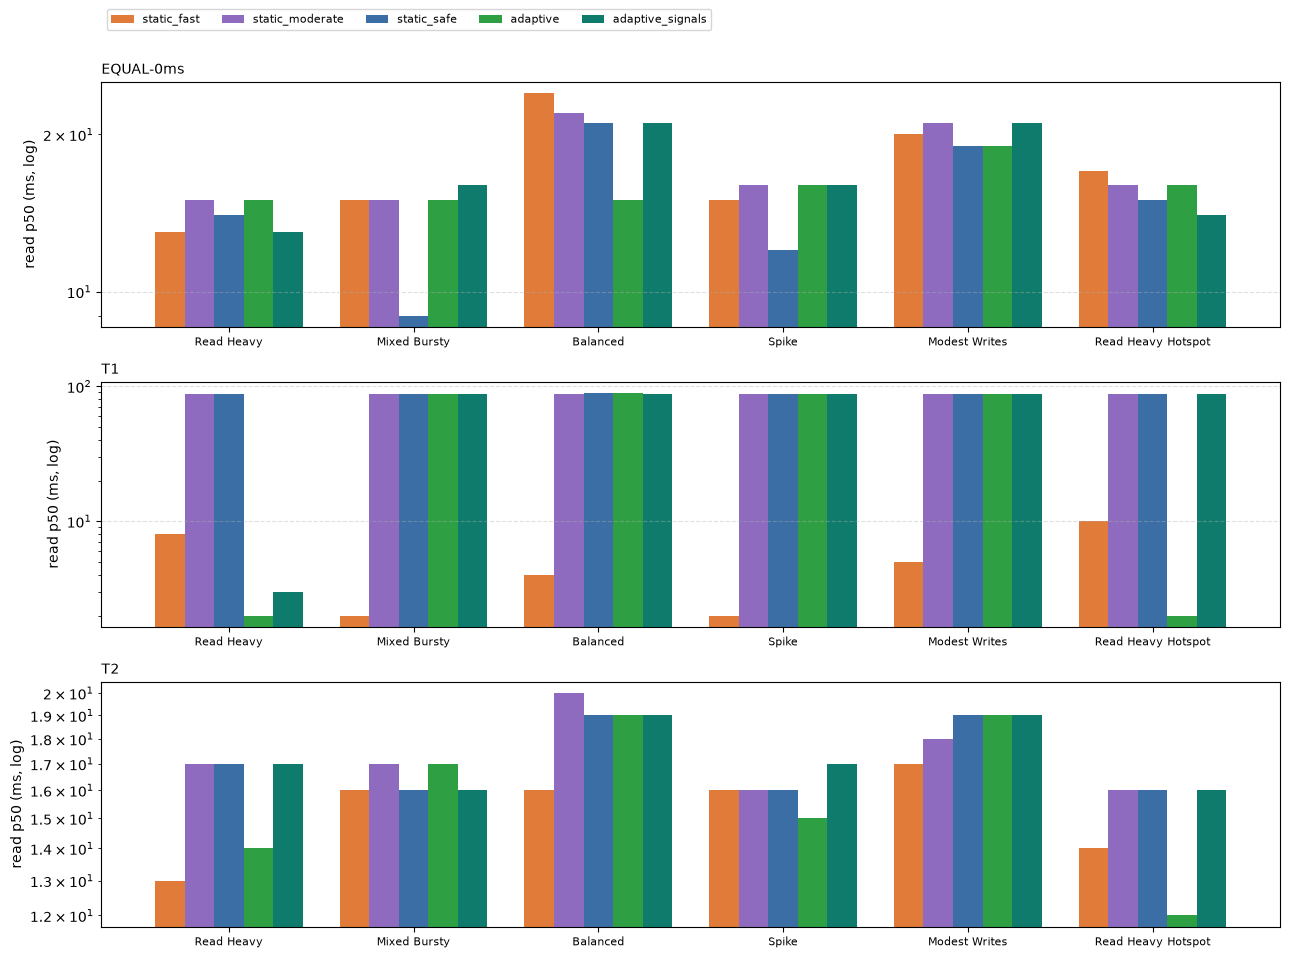

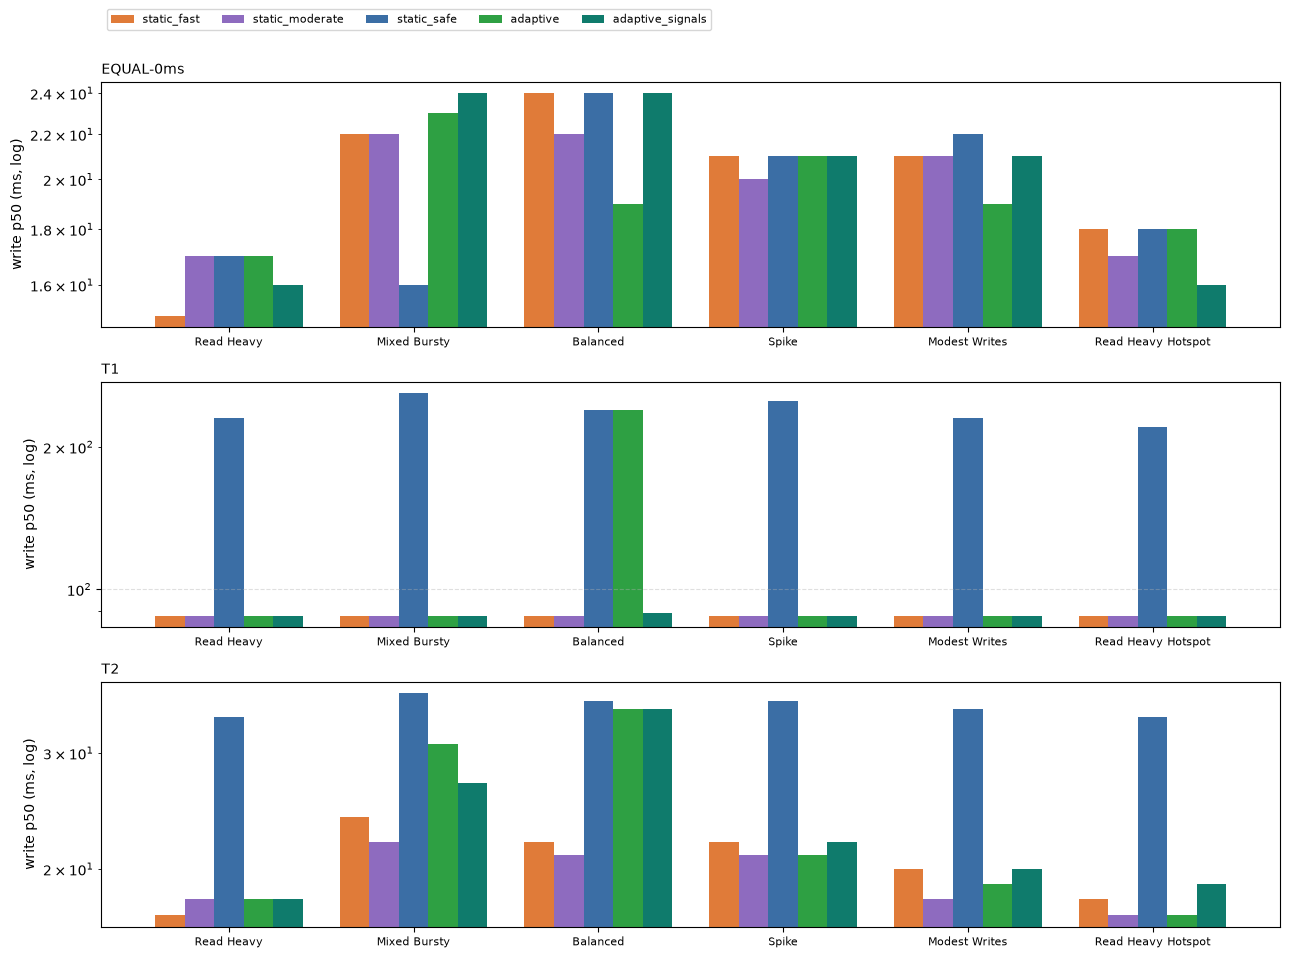

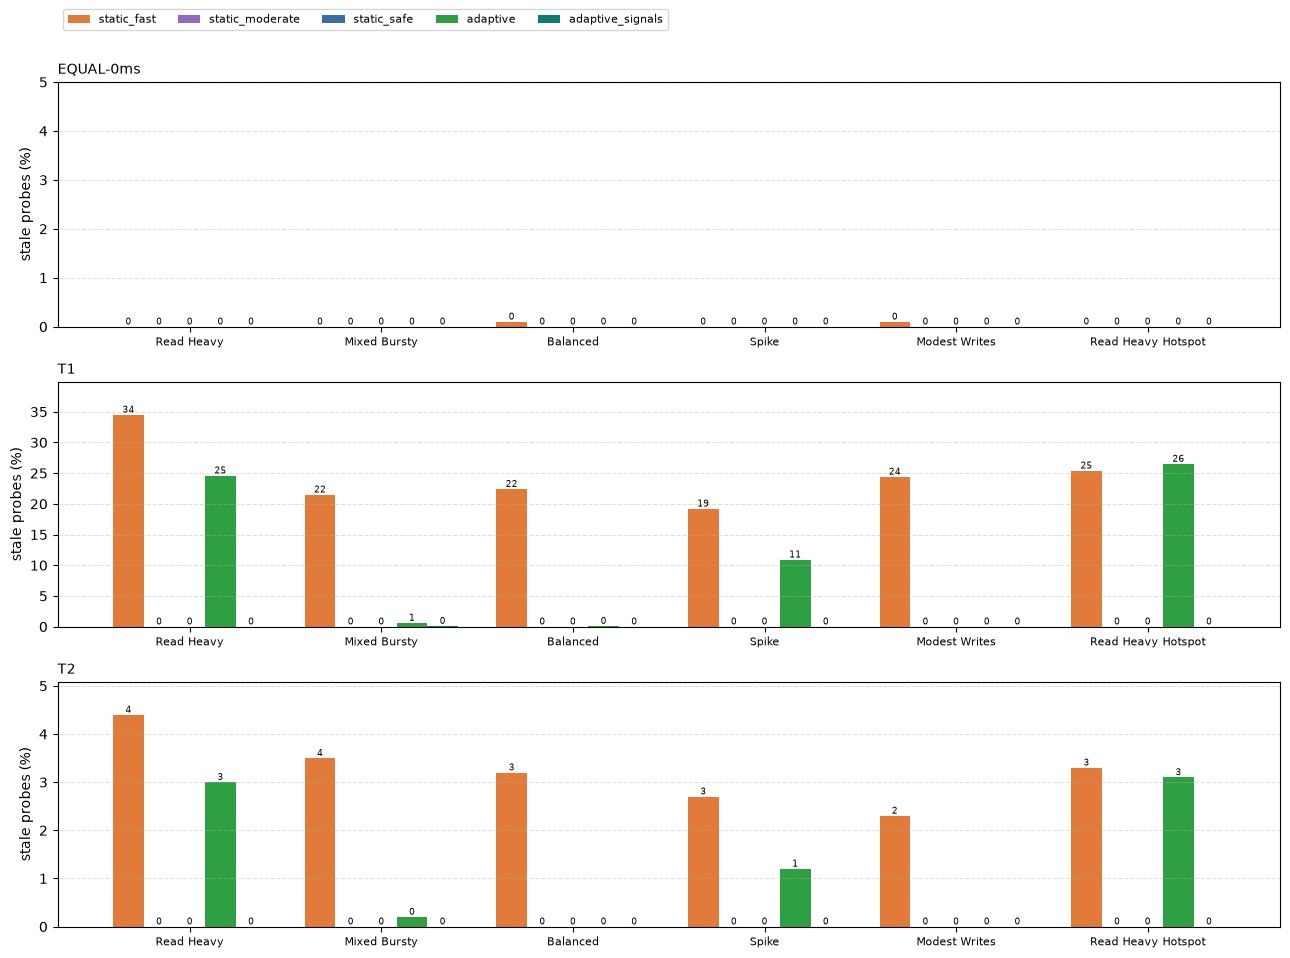

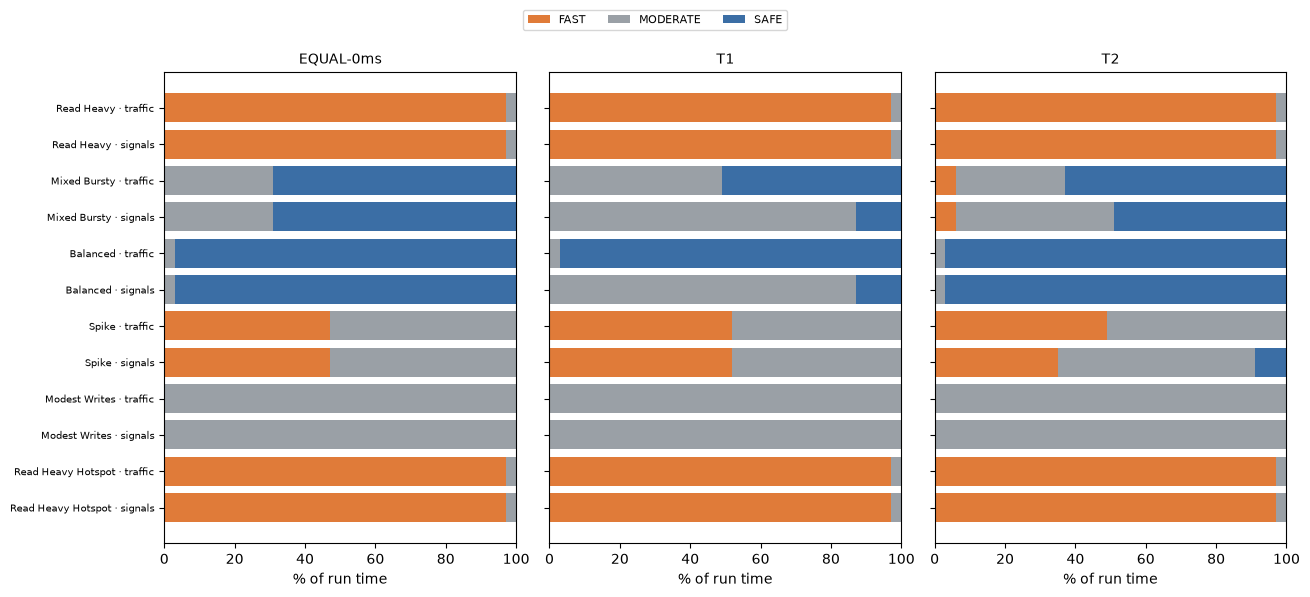

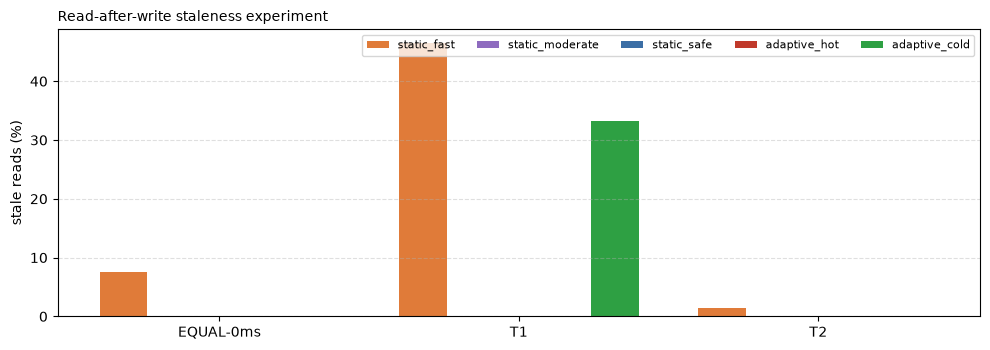

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline
if not df.empty:
    ev.figure_metric(df, OUT, "read_p50", "read p50 (ms, log)", "read_p50.png", log_scale=True); plt.show()
    ev.figure_metric(df, OUT, "write_p50", "write p50 (ms, log)", "write_p50.png", log_scale=True); plt.show()
    ev.figure_metric(df, OUT, "stale_pct", "stale probes (%)", "stale_probes.png", value_labels=True); plt.show()
    ev.figure_settings(df, OUT); plt.show()
if not st.empty:
    ev.figure_staleness(st, OUT); plt.show()

### 7.4 Staleness experiment

In [11]:
if st.empty:
    display(Markdown("_Not run._"))
else:
    display(st.pivot_table(index="config", columns="setup", values="stale_pct", sort=False)
            .style.format("{:.1f}%").set_caption(f"stale reads (%) — {plan.staleness_trials} trials each (adaptive_cold: {min(plan.staleness_trials, 60)})"))

setup,EQUAL-0ms,T1,T2
config,,,
static_fast,7.5%,46.5%,1.5%
static_moderate,0.0%,0.0%,0.0%
static_safe,0.0%,0.0%,0.0%
adaptive_hot,0.0%,0.0%,0.0%
adaptive_cold,0.0%,33.3%,0.0%


### 7.5 Why adaptive_signals switched (every switch, every run)

In [12]:
import csv as _csv
rows = []
for path in sorted(OUT.glob("topology_*/rep*/adaptive_signals_*_switches.csv")):
    preset = path.name[len("adaptive_signals_"):-len("_switches.csv")]
    with open(path, newline="", encoding="utf-8") as f:
        for r in _csv.DictReader(f):
            if r["event"] == "switch":
                rows.append({"setup": path.parent.parent.name[len("topology_"):], "preset": preset,
                             "at s": float(r["seconds"]), "to": r["settings"], "reason": r["reason"]})
sw = pd.DataFrame(rows)
if sw.empty:
    display(Markdown("_No switches recorded._"))
else:
    display(Markdown(f"{len(sw)} switches in total. First 60:"))
    display(sw.head(60).style.hide(axis="index").format({"at s": "{:.0f}"}))

70 switches in total. First 60:

setup,preset,at s,to,reason
EQUAL-0ms,BALANCED,5,SAFE,write share 0.52 > 0.40
EQUAL-0ms,MIXED_BURSTY,5,SAFE,write share 0.65 > 0.40
EQUAL-0ms,MIXED_BURSTY,30,MODERATE,write share 0.18 between 0.15 and 0.40
EQUAL-0ms,MIXED_BURSTY,40,SAFE,write share 0.54 > 0.40
EQUAL-0ms,MIXED_BURSTY,60,MODERATE,write share 0.17 between 0.15 and 0.40
EQUAL-0ms,MIXED_BURSTY,70,SAFE,write share 0.53 > 0.40
EQUAL-0ms,MIXED_BURSTY,90,MODERATE,write share 0.18 between 0.15 and 0.40
EQUAL-0ms,MIXED_BURSTY,100,SAFE,write share 0.54 > 0.40
EQUAL-0ms,MIXED_BURSTY,120,MODERATE,write share 0.18 between 0.15 and 0.40
EQUAL-0ms,MIXED_BURSTY,130,SAFE,write share 0.53 > 0.40


## 8. Store the record and finish

In [13]:
meta = ev.write_meta(OUT, plan, analysed=dt.datetime.now().isoformat(timespec="seconds"))
if STORE_RECORD:
    dest = ev.store_record(OUT, tag)
    display(Markdown(f"Committable record written to `{dest.relative_to(ev.REPO_ROOT)}` (tables, figures, small CSVs)."))
display(Markdown(f"""**Raw results:** `{OUT}`  \n**Phase times:** {meta.get('phase_seconds')}  \n**Git commit:** `{meta.get('git_commit')}`"""))

Committable record written to `docs\results\signals\FULL_2026-10-19_1452` (tables, figures, small CSVs).

**Raw results:** `C:\Users\admin\Desktop\Resume\MongoLayer\results\signals_eval\FULL_2026-10-19_1452`  
**Phase times:** {'preflight': 26, 'live_checks': 116, 'load_tests': 15332, 'staleness': 639}  
**Git commit:** `d9f7baf+uncommitted`